- 全村的新希望

In [ ]:
import time
import math
import torch
import random
import numpy as np
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.optim import lr_scheduler
import matplotlib.patches as patches
from matplotlib.patches import Ellipse
from typing import Dict, Optional, Tuple, Union
from dataclasses import dataclass, field
from collections import defaultdict

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field, plot_event_time2d
from methods.affinegs.cmax import ContrastMaximizationLoss
from utils.add_noise import add_event_noise
# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from utils.metrics import PIVmetric
# 检查CUDA是否可用
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

In [ ]:
# Efficiency table benchmark
# ILK/OF are non-parametric classical methods: learnable params are N/A.
# Throughput measures dense velocity-field reconstruction speed normalized by output resolution.
# Default data protocol:
#   - 256 x 256: synthetic simulator, 0-3 ms
#   - 1280 x 720: real EBIV recording, 10-20 ms
import gc
import time
import math
import torch
import numpy as np

from IPython.display import Markdown, display
from addict import Dict

from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from methods.inr.inr import MLP_Conv
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow
from methods import ilk_vg, of_vg, inr_vg


def _compute_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _format_resolution(H, W):
    return f"{W} x {H}"


def _format_time(seconds):
    return f"{seconds:.1f}"


def _format_param_count(n):
    if n is None:
        return "N/A"
    if n >= 1_000_000:
        return f"{n / 1_000_000:.1f}M"
    if n >= 1_000:
        return f"~{n / 1_000:.1f}K"
    return str(n)


def _format_throughput(H, W, seconds):
    if seconds <= 0:
        return "N/A"
    return f"{(H * W / 1e6) / seconds:.2f}"


def _count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def _inr_param_label():
    model = MLP_Conv(ne=64, beta=100)
    return _format_param_count(_count_trainable_params(model))


def _affine_param_label(result):
    model = result.model
    n_total = _count_trainable_params(model)
    n_gauss = int(model.num_gaussians)
    if n_gauss <= 0:
        return _format_param_count(n_total)
    per_gaussian = n_total / n_gauss
    return f"{per_gaussian:.0f}N ({_format_param_count(n_total)})"


def _to_event_tensor(evts):
    if isinstance(evts, torch.Tensor):
        return evts.float()
    return torch.as_tensor(evts, dtype=torch.float32)


def _make_synthetic_events(H, W, time_window=(0.0, 3.0), density=0.02, max_v=5.0):
    t0, t1 = map(float, time_window)
    p = min(H, W)
    flow = FlowManager(mode="analytical", name="cellular_flow", vmax=max_v, p=p)
    cfg = config_events()
    cfg.height = int(H)
    cfg.width = int(W)
    cfg.time_length = float(t1)
    cfg.density = float(density)
    cfg.d = 0.5
    cfg.device = "cuda:0" if torch.cuda.is_available() else "cpu"

    loader = EventManager(source_type="simulator", path=None, cfg=cfg, flow_func=flow.evaluate)
    evts, _ = loader.load()
    evts = _to_event_tensor(evts)
    return evts[(evts[:, 2] > t0) & (evts[:, 2] < t1)]


def _load_recorded_events(source_type, path, time_window):
    t0, t1 = map(float, time_window)
    loader = EventManager(source_type=source_type, path=path)
    evts, _ = loader.load()
    evts = _to_event_tensor(evts)
    return evts[(evts[:, 2] > t0) & (evts[:, 2] < t1)]


def _load_benchmark_events(case):
    source = case.source.lower()
    if source == "synthetic":
        return _make_synthetic_events(
            H=case.H,
            W=case.W,
            time_window=case.time_window,
            density=case.get("density", 0.02),
            max_v=case.get("max_v", 5.0),
        )
    if source == "recorded":
        return _load_recorded_events(
            source_type=case.source_type,
            path=case.path,
            time_window=case.time_window,
        )
    raise ValueError(f"Unknown benchmark source: {case.source}")


def _events_for_learning_method(events):
    return events.to(_compute_device())


def _format_peak_memory(mb):
    if mb is None:
        return "N/A"
    if mb >= 1024:
        return f"{mb / 1024:.2f} GB"
    return f"{mb:.0f} MB"


def _measure_call(fn, *args, track_peak_memory=False, **kwargs):
    gc.collect()
    use_cuda_memory = bool(track_peak_memory and torch.cuda.is_available())
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    peak_mb = None
    if use_cuda_memory:
        peak_mb = torch.cuda.max_memory_reserved() / (1024 ** 2)
    return elapsed, peak_mb, result


def _run_affinegs(events, H, W):
    cfg = GaussianFlowConfig(H=H, W=W, verbose=False)
    return run_gaussian_flow(events=events, cfg=cfg, flowgt=None)


def build_efficiency_table(methods_to_run=("ILK", "OF", "INR", "AffineGS"), benchmark_cases=None):
    if benchmark_cases is None:
        benchmark_cases = default_benchmark_cases

    rows = []
    inr_params_label = _inr_param_label()

    for case in benchmark_cases:
        H, W = int(case.H), int(case.W)
        t0, t1 = case.time_window
        print(f"Loading {case.data_name}: {_format_resolution(H, W)}, {t0}-{t1} ms ...")
        events = _load_benchmark_events(case)
        print(f"  events: {tuple(events.shape)}")

        for method_name in methods_to_run:
            method_key = method_name.lower()
            print(f"Running {method_name} on {case.data_name} ...")

            if method_key == "ilk":
                elapsed, peak_mb, _ = _measure_call(ilk_vg, events, H=H, W=W, track_peak_memory=False)
                params_label = "N/A"
            elif method_key == "of":
                elapsed, peak_mb, _ = _measure_call(of_vg, events, H=H, W=W, track_peak_memory=False)
                params_label = "N/A"
            elif method_key == "inr":
                elapsed, peak_mb, _ = _measure_call(inr_vg, _events_for_learning_method(events), H=H, W=W, track_peak_memory=True)
                params_label = inr_params_label
            elif method_key in ("affinegs", "affinegs (ours)"):
                elapsed, peak_mb, result = _measure_call(_run_affinegs, _events_for_learning_method(events), H, W, track_peak_memory=True)
                params_label = _affine_param_label(result)
            else:
                raise ValueError(f"Unknown method: {method_name}")

            rows.append({
                "Method": "AffineGS (Ours)" if method_key.startswith("affinegs") else method_name,
                "Data": case.data_name,
                "Resolution": _format_resolution(H, W),
                "Time Window": f"{t0}-{t1} ms",
                "Time (s)↓": _format_time(elapsed),
                "Learnable Params↓": params_label,
                "Peak Memory↓": _format_peak_memory(peak_mb),
                "Throughput (MPix/s)↑": _format_throughput(H, W, elapsed),
            })

            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    return rows


def display_efficiency_table(rows):
    headers = ["Method", "Data", "Resolution", "Time Window", "Time (s)↓", "Learnable Params↓", "Peak Memory↓", "Throughput (MPix/s)↑"]
    markdown = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for row in rows:
        markdown.append("| " + " | ".join(str(row[h]) for h in headers) + " |")
    display(Markdown("\n".join(markdown)))
    return markdown


# 256 x 256 uses synthetic events over 0-3 ms.
# 1280 x 720 uses the current EXP3 EBIV real-data protocol over 10-20 ms.
default_benchmark_cases = [
    Dict(
        data_name="Synthetic-3ms",
        source="synthetic",
        H=256,
        W=256,
        time_window=(0.0, 3.0),
        density=0.02,
        max_v=5.0,
    ),
    Dict(
        data_name="EBIV-real-10ms",
        source="recorded",
        source_type="real",
        path="./data/real_old/ebiv_wallflow4_dense.h5",
        H=720,
        W=1280,
        time_window=(10.0, 20.0),
    ),
    # To benchmark the water EVK5 recording instead, replace the EBIV case above with:
    # Dict(data_name="Water-real-10ms", source="recorded", source_type="evk5",
    #      path="./data/nn1.hdf5", H=720, W=1280, time_window=(10.0, 20.0)),
]

# Edit this line when you only want a quick partial benchmark.
methods_to_run = ("ILK", "OF", "INR", "AffineGS")

benchmark_rows = build_efficiency_table(
    methods_to_run=methods_to_run,
    benchmark_cases=default_benchmark_cases,
)
_ = display_efficiency_table(benchmark_rows)


tensor(8.9554e-05, device='cuda:0') tensor(3.0000, device='cuda:0')
原始事件:torch.Size([191920, 4])
当前使用的事件数量:torch.Size([115280, 4])
最大速度值: 3.4960200786590576


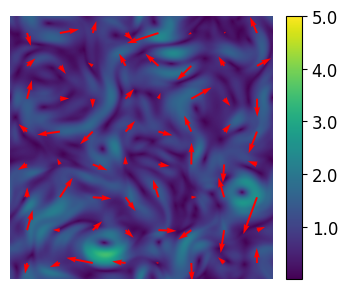

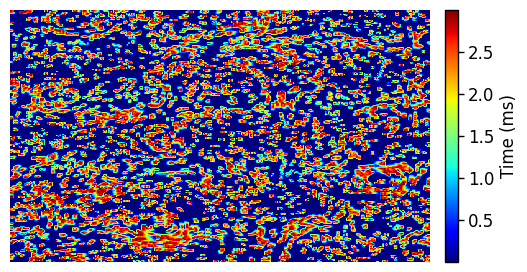

In [2]:
max_v = 5

flow0 = FlowManager(mode="analytical", name="solid_rot", x_c=128, y_c=128, omega=0.005525*max_v)
flow1 = FlowManager(mode="analytical", name="cellular_flow", vmax=max_v, p=256)
flow2 = FlowManager(mode="analytical", name="uniform", uc=max_v/np.sqrt(2), vc=max_v/np.sqrt(2))

flow3 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")
flow4 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_mhd1024_hd_00001_flow.npz")
flow5 = FlowManager(mode="data", data_path="./data/datasets/backstep_Re1500_00001_flow.npz")
flow6 = FlowManager(mode="data", data_path="./data/datasets/DNS_turbulence_00001_flow.npz")

flow7 = FlowManager(mode="analytical", name="lamb_oseen", x_c=128, y_c=128, Gamma=3e3, rc=60)
flow8 = FlowManager(mode="analytical", name="shear_flow", vmax=max_v, p=256)
flow9 = FlowManager(mode="analytical", name="gs_flow", max_v=5.0, n_vortex=20, seed=1)
flow10 = FlowManager(mode="analytical", name="one_shear", vmax=5, vmin=0.0, p=256)

flow11 = FlowManager(mode="data", data_path="./data/datasets/cylinder_Re300_00001_flow.npz")
flow12 = FlowManager(mode="data", data_path="./data/datasets/SQG_00001_flow.npz")
flow13 = FlowManager(mode="analytical", name="sin_flow", x_c=128,y_c=128, a=16, b=128, scale=max_v)

flow_func = flow6.evaluate
cfg_evts = config_events()
cfg_evts.time_length=5
cfg_evts.d = 0.5
cfg_evts.density = 0.05

event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
evts, (u, v) = event_loader.load()
flowgt = torch.stack([u, v], dim=0).to(device)  # 通道0=vel_h, 通道1=vel_w

events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
print(events[:, 2].min(), events[:, 2].max())

h_gt = u.cpu().numpy()
w_gt = v.cpu().numpy()

print(f"原始事件:{evts.shape}")
print(f"当前使用的事件数量:{events.shape}")
print(f"最大速度值: {torch.max(torch.sqrt(u**2 + v** 2)).item()}")

plot_flow_field(h_gt, w_gt, output_file=None, colorbar_flag=True, step=1, v_max=5,  quiver_step=32, scale=None, figsize=(5, 3))
plot_event_time2d(events, output_file=None, vmin=None, vmax=None)

In [3]:
from pathlib import Path
from matplotlib import colors as mpl_colors
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter

# Combined flow-magnitude and event-time visualization for flow3, flow6, flow12.
# Outputs:
#   - three flow magnitude images with arrows and without colorbar
#   - three event time images without colorbar
#   - one standalone magnitude colorbar
#   - one standalone event-time colorbar

out_dir = Path("./output/Test_combined")
out_dir.mkdir(parents=True, exist_ok=True)

selected_flows = {
    "flow3": flow3,
    "flow6": flow6,
    "flow12": flow12,
}

FIGSIZE = (5, 3)
FONT_SIZE = 12
FLOW_VMIN, FLOW_VMAX = 0.0, 5.0
TIME_VMIN, TIME_VMAX = 0.0, 3.0
FLOW_CMAP = "viridis"
TIME_CMAP = "jet"

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
})


def _to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def _flow_to_arrays(flow_obj, H=256, W=256):
    h = torch.linspace(0, H - 1, H, device=device)
    w = torch.linspace(0, W - 1, W, device=device)
    hh, ww = torch.meshgrid(h, w, indexing="ij")
    u, v = flow_obj.evaluate(hh, ww)
    return _to_numpy(u), _to_numpy(v)


def _events_for_flow(flow_obj, time_length=5, density=0.05, d=0.5):
    cfg = config_events()
    cfg.time_length = time_length
    cfg.density = density
    cfg.d = d
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg, flow_func=flow_obj.evaluate)
    evts, _ = event_loader.load()
    return evts[(evts[:, 2] >= TIME_VMIN) & (evts[:, 2] <= TIME_VMAX)]


def save_flow_magnitude_image(u, v, save_path, quiver_step=32):
    mag = np.sqrt(u ** 2 + v ** 2)
    H, W = mag.shape
    x = np.arange(H)
    y = np.arange(W)
    xx, yy = np.meshgrid(x, y, indexing="ij")

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.imshow(mag, cmap=FLOW_CMAP, vmin=FLOW_VMIN, vmax=FLOW_VMAX, origin="lower")
    q = slice(quiver_step // 2, None, quiver_step)
    ax.quiver(
        yy[q, q],
        xx[q, q],
        v[q, q],
        -u[q, q],
        color="red",
        scale=None,
    )
    ax.set_xlim([-0.6, W - 0.4])
    ax.set_ylim([-0.6, H - 0.4])
    ax.axis("off")
    ax.invert_yaxis()
    fig.tight_layout(pad=0)
    fig.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0)
    plt.close(fig)


def save_event_time_image(events, save_path):
    ev = _to_numpy(events)
    h = ev[:, 0].astype(int)
    w = ev[:, 1].astype(int)
    t = ev[:, 2]

    img = np.zeros((256, 256), dtype=float)
    mask = (h >= 0) & (h < 256) & (w >= 0) & (w < 256) & (t >= TIME_VMIN) & (t <= TIME_VMAX)
    np.maximum.at(img, (h[mask], w[mask]), t[mask])

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.imshow(img, cmap=TIME_CMAP, vmin=TIME_VMIN, vmax=TIME_VMAX, origin="lower")
    ax.axis("off")
    fig.tight_layout(pad=0)
    fig.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0)
    plt.close(fig)


def save_standalone_colorbar(vmin, vmax, cmap, label, save_path, ticks, fmt="%.1f"):
    fig, ax = plt.subplots(figsize=(0.36, 3.0))
    norm = mpl_colors.Normalize(vmin=vmin, vmax=vmax)
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=ax, ticks=ticks)
    cbar.ax.tick_params(labelsize=FONT_SIZE)
    cbar.ax.yaxis.set_major_formatter(FormatStrFormatter(fmt))
    cbar.set_label(label, fontsize=FONT_SIZE, rotation=90, labelpad=8)
    fig.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0.04)
    plt.close(fig)


for name, flow_obj in selected_flows.items():
    u, v = _flow_to_arrays(flow_obj)
    events_i = _events_for_flow(flow_obj)

    save_flow_magnitude_image(u, v, out_dir / f"{name}_flow_magnitude.svg")
    save_event_time_image(events_i, out_dir / f"{name}_event_time.svg")

save_standalone_colorbar(
    FLOW_VMIN,
    FLOW_VMAX,
    FLOW_CMAP,
    "magnitude [px/ms]",
    out_dir / "colorbar_flow_magnitude.svg",
    ticks=np.linspace(FLOW_VMIN, FLOW_VMAX, 6),
    fmt="%.1f",
)

save_standalone_colorbar(
    TIME_VMIN,
    TIME_VMAX,
    TIME_CMAP,
    "time [ms]",
    out_dir / "colorbar_event_time.svg",
    ticks=np.linspace(TIME_VMIN, TIME_VMAX, 4),
    fmt="%.1f",
)

print(f"Saved combined visualizations to: {out_dir}")


Saved combined visualizations to: output/Test_combined


# 生成图1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, Ellipse

# =========================================================
# 全局统一配置
# 目标：
# 1. 所有输出图像大小完全一致
# 2. 所有图中的方框大小完全一致
# 3. 所有同类线条的线型、线宽一致
# 4. 所有图使用同一套速度尺度和同一个 quiver 缩放
# 5. 尽量保证方框都在虚线/椭圆覆盖范围内
# 6. 尽量保证各图支撑区域到图像边界的留白一致
# =========================================================

# ---------------------------
# 输出尺寸
# ---------------------------
FIGSIZE = (6, 6)     # inch
PREVIEW_DPI = 150
SAVE_DPI = 300

# ---------------------------
# 几何参数
# ---------------------------
ROI_HALF_SIDE = 1.0         # 中央方框半边长，所有图一致
INSIDE_MARGIN = 0.08        # 保证方框尽量落在虚线/椭圆覆盖范围内的安全边距

# 统一支撑区域半径（关键）
# 要让整个方框在圆内，至少需要 sqrt(2)*ROI_HALF_SIDE
SUPPORT_HALF_RANGE = np.sqrt(2) * ROI_HALF_SIDE + INSIDE_MARGIN

# 图像显示范围：支撑区域外再留统一边距
DISPLAY_PAD = 0.18
DISPLAY_HALF_RANGE = SUPPORT_HALF_RANGE + DISPLAY_PAD

# ---------------------------
# 速度尺度（所有图统一）
# ---------------------------
V_MAX = 2.0
QUIVER_SCALE = 18
GRID_N = 10   # 偶数，减少中轴箭头重合

# ---------------------------
# 颜色
# ---------------------------
COLOR_ROI = '#283655'
COLOR_BOUNDARY = '#283655'
COLOR_AFFINE_ARROW = '#C44E52'
PALETTE = [
    '#D55E00',  # 朱红
    '#0072B2',  # 蓝
    '#009E73',  # 绿
    '#CC79A7',  # 紫
]

# ---------------------------
# 统一线条样式
# ---------------------------
ROI_LINEWIDTH = 2.5
SUPPORT_LINEWIDTH = 2.0
ROI_LINESTYLE = '-'
SUPPORT_LINESTYLE = '--'

# ---------------------------
# 统一箭头样式
# ---------------------------
QUIVER_KW = dict(
    scale=QUIVER_SCALE,
    width=0.005,
    headwidth=5,
    headlength=6,
    pivot='mid'
)

# =========================================================
# 基础工具函数
# =========================================================
def create_canvas():
    """
    创建统一画布。
    使用 add_axes([0,0,1,1]) 保证画布铺满，避免不同图 tight 裁剪后尺寸不一致。
    """
    fig = plt.figure(figsize=FIGSIZE, dpi=PREVIEW_DPI, facecolor='none')
    ax = fig.add_axes([0, 0, 1, 1], facecolor='none')

    ax.set_aspect('equal')
    ax.set_xlim(-DISPLAY_HALF_RANGE, DISPLAY_HALF_RANGE)
    ax.set_ylim(-DISPLAY_HALF_RANGE, DISPLAY_HALF_RANGE)
    ax.axis('off')

    # 统一 ROI 方框
    roi = Rectangle(
        (-ROI_HALF_SIDE, -ROI_HALF_SIDE),
        2 * ROI_HALF_SIDE,
        2 * ROI_HALF_SIDE,
        fill=False,
        edgecolor=COLOR_ROI,
        linewidth=ROI_LINEWIDTH,
        linestyle=ROI_LINESTYLE,
        zorder=3
    )
    ax.add_patch(roi)

    return fig, ax


def save_figure(fig, filename):
    """
    统一保存，不使用 bbox_inches='tight'，保证所有输出尺寸一致。
    """
    fig.savefig(
        filename,
        dpi=SAVE_DPI,
        transparent=True
    )


def make_grid():
    """
    统一箭头采样网格。
    """
    x = np.linspace(-DISPLAY_HALF_RANGE, DISPLAY_HALF_RANGE, GRID_N)
    y = np.linspace(-DISPLAY_HALF_RANGE, DISPLAY_HALF_RANGE, GRID_N)
    return np.meshgrid(x, y)


# =========================================================
# 数值检查函数（可选）
# =========================================================
def check_square_in_circle(roi_half_side, r):
    """
    检查方框是否完全在圆内。
    """
    return r >= np.sqrt(2) * roi_half_side


def check_square_in_circle_union(roi_half_side, centers, radius, n=401):
    """
    检查方框是否完全在多个圆的并集内。
    """
    xs = np.linspace(-roi_half_side, roi_half_side, n)
    ys = np.linspace(-roi_half_side, roi_half_side, n)
    X, Y = np.meshgrid(xs, ys)

    covered = np.zeros_like(X, dtype=bool)
    for cx, cy in centers:
        covered |= (X - cx) ** 2 + (Y - cy) ** 2 <= radius ** 2

    return covered.all()


def check_square_in_ellipse_union(roi_half_side, ellipses, n=401):
    """
    检查方框是否完全在多个椭圆的并集内。
    ellipses: [(cx, cy, ew, eh), ...]
    """
    xs = np.linspace(-roi_half_side, roi_half_side, n)
    ys = np.linspace(-roi_half_side, roi_half_side, n)
    X, Y = np.meshgrid(xs, ys)

    covered = np.zeros_like(X, dtype=bool)
    for cx, cy, ew, eh in ellipses:
        covered |= ((X - cx) / (ew / 2)) ** 2 + ((Y - cy) / (eh / 2)) ** 2 <= 1.0

    return covered.all()


# =========================================================
# 1) 无雅可比：刚性旋转的分片常速度表征（4个圆）
#    尽量让方框落在圆并集内，并让并集外接框统一
# =========================================================
def draw_constgs_rigid(ax):
    centers = [
        (0.5, 0.5),
        (-0.5, 0.5),
        (-0.5, -0.5),
        (0.5, -0.5),
    ]

    # 让圆外沿正好顶到统一外包框
    radius = SUPPORT_HALF_RANGE - 0.5

    # 与 affine 刚性旋转统一速度尺度
    omega = V_MAX / SUPPORT_HALF_RANGE

    X, Y = make_grid()

    for i, (cx, cy) in enumerate(centers):
        color = PALETTE[i % len(PALETTE)]

        patch = Circle(
            (cx, cy),
            radius,
            fill=False,
            edgecolor=color,
            linewidth=SUPPORT_LINEWIDTH,
            linestyle=SUPPORT_LINESTYLE,
            zorder=2
        )
        ax.add_patch(patch)

        # 每个高斯内部常速度
        u_val = -omega * cy
        v_val =  omega * cx

        mask = (X - cx) ** 2 + (Y - cy) ** 2 <= radius ** 2
        U = np.where(mask, u_val, np.nan)
        V = np.where(mask, v_val, np.nan)

        ax.quiver(X, Y, U, V, color=color, zorder=1, **QUIVER_KW)

    return centers, radius


# =========================================================
# 2) 无雅可比：剪切流的分片常速度表征（3个椭圆）
#    参数选取尽量保证方框在椭圆并集内，且并集外接框统一
# =========================================================
def draw_constgs_shear(ax):
    centers_x = [-0.70, 0.0, 0.70]
    centers_y = [0.0, 0.0, 0.0]

    # 左右外沿到统一支撑边界
    ellipse_w = 2 * (SUPPORT_HALF_RANGE - 0.70)
    # 上下外沿到统一支撑边界
    ellipse_h = 2 * SUPPORT_HALF_RANGE

    X, Y = make_grid()

    # 统一速度尺度：左大右小
    ratios = [1.0, 0.625, 0.25]

    ellipses = []

    for i, (cx, cy, ratio) in enumerate(zip(centers_x, centers_y, ratios)):
        color = PALETTE[i % len(PALETTE)]

        patch = Ellipse(
            (cx, cy),
            ellipse_w,
            ellipse_h,
            fill=False,
            edgecolor=color,
            linewidth=SUPPORT_LINEWIDTH,
            linestyle=SUPPORT_LINESTYLE,
            zorder=2
        )
        ax.add_patch(patch)

        u_val = 0.0
        v_val = -V_MAX * ratio

        mask = ((X - cx) / (ellipse_w / 2)) ** 2 + ((Y - cy) / (ellipse_h / 2)) ** 2 <= 1.0
        U = np.where(mask, u_val, np.nan)
        V = np.where(mask, v_val, np.nan)

        ax.quiver(X, Y, U, V, color=color, zorder=1, **QUIVER_KW)

        ellipses.append((cx, cy, ellipse_w, ellipse_h))

    return ellipses


# =========================================================
# 3) 有雅可比：刚性旋转的连续仿射表征（统一圆域）
# =========================================================
def draw_affine_rigid(ax):
    boundary_r = SUPPORT_HALF_RANGE
    omega = V_MAX / boundary_r

    X, Y = make_grid()

    patch = Circle(
        (0, 0),
        boundary_r,
        fill=False,
        edgecolor=COLOR_BOUNDARY,
        linewidth=SUPPORT_LINEWIDTH,
        linestyle=SUPPORT_LINESTYLE,
        zorder=2
    )
    ax.add_patch(patch)

    U = -omega * Y
    V =  omega * X

    mask = X ** 2 + Y ** 2 <= boundary_r ** 2
    U = np.where(mask, U, np.nan)
    V = np.where(mask, V, np.nan)

    ax.quiver(X, Y, U, V, color=COLOR_AFFINE_ARROW, zorder=1, **QUIVER_KW)

    return boundary_r


# =========================================================
# 4) 有雅可比：剪切流的连续仿射表征（统一圆域）
# =========================================================
def draw_affine_shear(ax):
    boundary_r = SUPPORT_HALF_RANGE

    X, Y = make_grid()

    patch = Circle(
        (0, 0),
        boundary_r,
        fill=False,
        edgecolor=COLOR_BOUNDARY,
        linewidth=SUPPORT_LINEWIDTH,
        linestyle=SUPPORT_LINESTYLE,
        zorder=2
    )
    ax.add_patch(patch)

    # 左侧速度最大，右侧最小；所有图统一使用 V_MAX
    x_norm = (X + boundary_r) / (2 * boundary_r)   # [-r, r] -> [0, 1]
    ratio = 1.0 - 0.75 * x_norm                    # [1.0, 0.25]

    U = np.zeros_like(X)
    V = -V_MAX * ratio

    mask = X ** 2 + Y ** 2 <= boundary_r ** 2
    U = np.where(mask, U, np.nan)
    V = np.where(mask, V, np.nan)

    ax.quiver(X, Y, U, V, color=COLOR_AFFINE_ARROW, zorder=1, **QUIVER_KW)

    return boundary_r


# =========================================================
# 批量生成图像
# =========================================================
def generate_all_figures(show=True, print_checks=True):
    # 1. constGS rigid
    fig1, ax1 = create_canvas()
    centers_rigid, radius_rigid = draw_constgs_rigid(ax1)
    save_figure(fig1, 'constgs_rigid.svg')

    # 2. constGS shear
    fig2, ax2 = create_canvas()
    ellipses_shear = draw_constgs_shear(ax2)
    save_figure(fig2, 'constgs_shear.svg')

    # 3. affine rigid
    fig3, ax3 = create_canvas()
    boundary_r_rigid = draw_affine_rigid(ax3)
    save_figure(fig3, 'affine_rigid.svg')

    # 4. affine shear
    fig4, ax4 = create_canvas()
    boundary_r_shear = draw_affine_shear(ax4)
    save_figure(fig4, 'affine_shear.svg')

    if print_checks:
        print("=" * 60)
        print("统一参数检查")
        print("=" * 60)
        print(f"ROI_HALF_SIDE       = {ROI_HALF_SIDE:.4f}")
        print(f"SUPPORT_HALF_RANGE  = {SUPPORT_HALF_RANGE:.4f}")
        print(f"DISPLAY_HALF_RANGE  = {DISPLAY_HALF_RANGE:.4f}")
        print(f"V_MAX               = {V_MAX:.4f}")
        print(f"QUIVER_SCALE        = {QUIVER_SCALE:.4f}")
        print()

        print("=" * 60)
        print("覆盖性检查")
        print("=" * 60)
        print(f"Affine rigid: 方框是否在圆内       -> {check_square_in_circle(ROI_HALF_SIDE, boundary_r_rigid)}")
        print(f"Affine shear: 方框是否在圆内       -> {check_square_in_circle(ROI_HALF_SIDE, boundary_r_shear)}")
        print(f"ConstGS rigid: 方框是否在圆并集内  -> {check_square_in_circle_union(ROI_HALF_SIDE, centers_rigid, radius_rigid)}")
        print(f"ConstGS shear: 方框是否在椭圆并集内 -> {check_square_in_ellipse_union(ROI_HALF_SIDE, ellipses_shear)}")
        print()

    if show:
        plt.show()
    else:
        plt.close(fig1)
        plt.close(fig2)
        plt.close(fig3)
        plt.close(fig4)


if __name__ == "__main__":
    generate_all_figures(show=True, print_checks=True)

# 事件图

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import torch
except ImportError:
    torch = None


def plot_events_3d_clean(
    events,
    H=256,
    W=256,
    max_points=8000,
    elev=20,
    azim=-60,
    point_size=1.8,
    alpha=0.85,
    font_size=8,
):
    if torch is not None and isinstance(events, torch.Tensor):
        events = events.detach().cpu().numpy()
    else:
        events = np.asarray(events)

    assert events.ndim == 2 and events.shape[1] >= 4

    h = events[:, 0].astype(np.float64)
    w = events[:, 1].astype(np.float64)
    t = events[:, 2].astype(np.float64)
    p = events[:, 3]

    t_min = t.min()
    t_max = t.max()
    if t_max > t_min:
        t_vis = 3.0 * (t - t_min) / (t_max - t_min)
    else:
        t_vis = np.zeros_like(t)

    N = len(events)
    if N > max_points:
        idx = np.random.choice(N, size=max_points, replace=False)
        h = h[idx]
        w = w[idx]
        t_vis = t_vis[idx]
        p = p[idx]

    pos_mask = p > 0
    neg_mask = ~pos_mask

    fig = plt.figure(figsize=(4, 4), dpi=160, facecolor="white")
    ax = fig.add_subplot(111, projection="3d")

    ax.scatter(w[pos_mask], h[pos_mask], t_vis[pos_mask],
               c="red", s=point_size, alpha=alpha, marker=".", depthshade=False)
    ax.scatter(w[neg_mask], h[neg_mask], t_vis[neg_mask],
               c="blue", s=point_size, alpha=alpha, marker=".", depthshade=False)

    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.set_zlim(0, 3)

    ax.set_xticks([0, 100, 200])
    ax.set_yticks([0, 100, 200])
    ax.set_zticks([1, 2, 3])

    ax.set_xticklabels(["0", "100", "200"], fontsize=font_size)
    ax.set_yticklabels(["0", "100", "200"], fontsize=font_size)
    ax.set_zticklabels(["1", "2", "3"], fontsize=font_size)

    ax.set_xlabel("W [px]", fontsize=font_size, labelpad=-4)
    ax.set_ylabel("H [px]", fontsize=font_size, labelpad=-4)
    ax.zaxis.set_rotate_label(False)
    ax.set_zlabel("t [ms]", fontsize=font_size, rotation=90, labelpad=-4)

    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 0.85))

    ax.grid(False)
    ax.tick_params(axis="x", which="major", pad=-3, labelsize=font_size)
    ax.tick_params(axis="y", which="major", pad=-3, labelsize=font_size)
    ax.zaxis.set_tick_params(pad=-2, labelsize=font_size)

    for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
        axis.pane.fill = False
        axis.pane.set_edgecolor((0.82, 0.82, 0.82, 1.0))

    fig.subplots_adjust(left=0.0, right=1.0, bottom=0.0, top=1.0)
    plt.savefig("1.svg")

    plt.show()


# Generate sample events for testing
np.random.seed(42)
N = 10000
h_data = np.random.randint(0, 256, N)
w_data = np.random.randint(0, 256, N)
t_data = np.sort(np.random.uniform(0, 1000, N))
p_data = np.random.choice([-1, 1], N)
events = np.column_stack([h_data, w_data, t_data, p_data])

plot_events_3d_clean(
    events,
    H=256,
    W=256,
    max_points=5000,
    elev=18,
    azim=-73,
    point_size=1.5,
    font_size=12,
)

# IWE

In [ ]:
cmax_loss = ContrastMaximizationLoss(loss_type='l2_max', sigma=0.6, kernel_size=5).to(device)  # variance, l2_max, structure
loss = cmax_loss(events, flowgt, (256, 256), vis=True)
print(f"Calculated Loss: {loss.item()}")
# --- 可视化 ---
cmax_loss.plot_visualization(grid_step=32, grid_loss_n=None, save_dir="./output/fig2")